# **🎓 Student Final Grade Prediction (SES Data)**

**What is this notebook about?**
We use a dataset of ~12,000 Indian school students (grades 6–12) with family background (SES = Socio-Economic Status), school and study-habit information. 
Our goal is to **predict `final_grade_pct` (final grade %)** – a *regression* problem.

**Notebook roadmap**
1. Import libraries & load data
2. Data cleaning (duplicates, missing values, data leakage)
3. Exploratory Data Analysis (EDA)
4. Feature engineering & preprocessing
5. Train models: Baseline → Linear → Ridge → Random Forest → Gradient Boosting → XGBoost → LightGBM
6. Compare models, tune the best one
7. Feature importance
8. Bonus: predict the letter grade (A–F)
9. Conclusion

## **1. Import Libraries & Load Data**

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,accuracy_score, confusion_matrix
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEED = 42
np.random.seed(SEED)


# ============================================================
# 2. LOAD DATASET AUTOMATICALLY
# ============================================================

FILENAME = "student_grade_ses_dataset.csv"
path = None

# Search common Kaggle, Colab and local directories
SEARCH_DIRS = [
    "/kaggle/input",
    "/content",
    "/mnt/data",
    "/mnt/user-data/uploads",
    "."
]

for base_dir in SEARCH_DIRS:
    if not os.path.isdir(base_dir):
        continue

    for root, dirs, files in os.walk(base_dir):
        # Avoid scanning unnecessary hidden folders
        dirs[:] = [
            d for d in dirs
            if not d.startswith(".")
        ]

        if FILENAME in files:
            path = os.path.join(root, FILENAME)
            break

    if path is not None:
        break

# Stop with a helpful message if the file was not found
if path is None:
    raise FileNotFoundError(
        f"Could not find {FILENAME}.\n"
        "In Kaggle, add the dataset using Add Input.\n"
        "In Colab, upload the CSV file first.\n"
        "You can also set path manually to the CSV location."
    )

# Read CSV
df = pd.read_csv(path)

print("Dataset loaded successfully!")
print("File path:", path)
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
File path: /kaggle/input/datasets/chaitanyajamble/grade-prediction-based-on-socioeconomic-factors/student_grade_ses_dataset.csv
Dataset shape: (12025, 29)


,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


## **2. Data Cleaning**
Steps: remove duplicates → check missing values → remove columns that would *leak* the answer.

In [2]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

missing = df.isna().sum()
print("\nMissing values:\n", missing[missing > 0])

Duplicate rows: 25

Missing values:
 annual_family_income_inr    720
father_education_level      420
mother_education_level      360
father_occupation           480
mother_occupation           600
has_internet_access         180
distance_to_school_km       240
attendance_rate_pct         300
previous_year_grade_pct     360
dtype: int64


**⚠️ Data leakage:** `grade_class` (A–F) and `at_risk_flag` are created *directly from* `final_grade_pct`. If we used them as inputs, the model would just "cheat". 
We also drop `student_id` and `survey_date` (identifiers, no learning value).

In [3]:
df_class = df["grade_class"].copy()          # keep for the bonus section
df = df.drop(columns=["student_id", "survey_date", "grade_class", "at_risk_flag"])
print("Columns left:", df.shape[1])

Columns left: 25


## **3. Exploratory Data Analysis (EDA)**

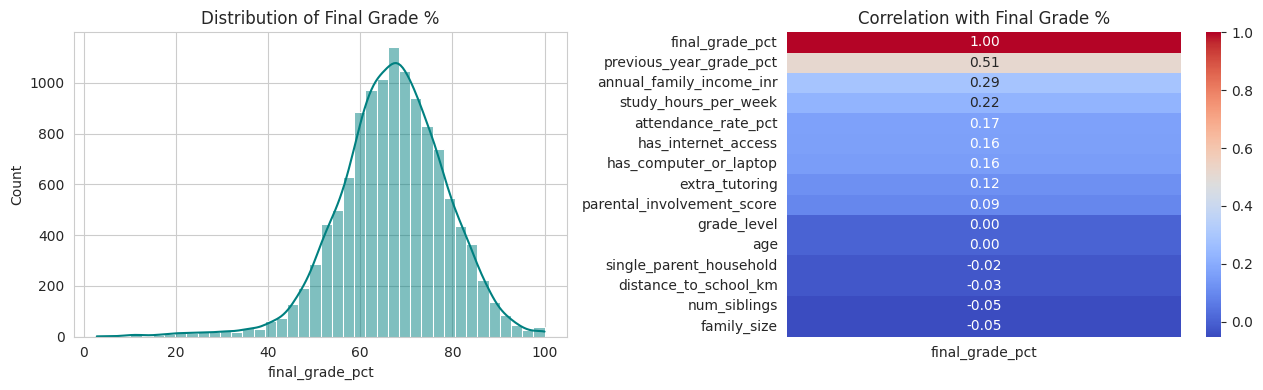

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["final_grade_pct"], bins=40, kde=True, ax=ax[0], color="teal")
ax[0].set_title("Distribution of Final Grade %")
sns.heatmap(df.corr(numeric_only=True)[["final_grade_pct"]].sort_values("final_grade_pct", ascending=False),
            annot=True, cmap="coolwarm", fmt=".2f", ax=ax[1])
ax[1].set_title("Correlation with Final Grade %")
plt.tight_layout(); plt.show()

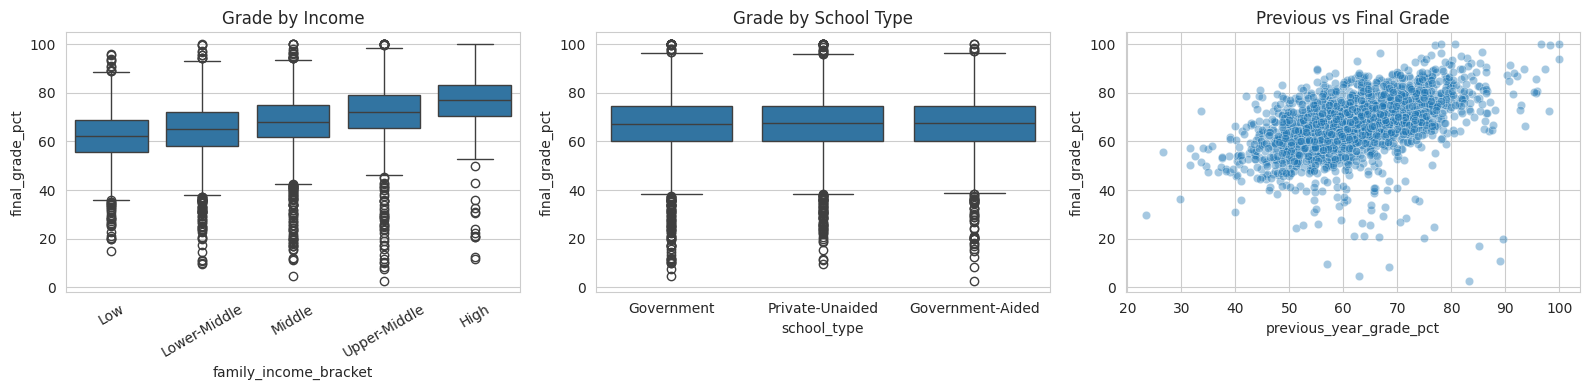

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x="family_income_bracket", y="final_grade_pct", ax=ax[0],
            order=["Low","Lower-Middle","Middle","Upper-Middle","High"]); ax[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=df, x="school_type", y="final_grade_pct", ax=ax[1])
sns.scatterplot(data=df.sample(2000, random_state=SEED), x="previous_year_grade_pct", y="final_grade_pct", alpha=.4, ax=ax[2])
ax[0].set_title("Grade by Income"); ax[1].set_title("Grade by School Type"); ax[2].set_title("Previous vs Final Grade")
plt.tight_layout(); plt.show()

**EDA takeaways:** final grades are roughly bell-shaped; **previous-year grade** is the strongest predictor, followed by **family income** and **study hours**. Richer families / private schools tend to score higher.

## **4. Feature Engineering & Preprocessing**
New simple features: log of income (income is very skewed), average parent education, and study hours × attendance.
Missing numbers → median, missing categories → "Missing". Categories are one-hot encoded.

In [6]:
edu_order = {"No Formal Education":0,"Primary":1,"Secondary":2,"Higher Secondary":3,"Bachelor's Degree":4,"Master's Degree":5,"Doctorate":6}
print("Education levels found:", sorted(set(df["father_education_level"].dropna())))

X = df.drop(columns="final_grade_pct").copy()
y = df["final_grade_pct"]

X["log_income"] = np.log1p(X["annual_family_income_inr"])
X["parent_edu_avg"] = (X["father_education_level"].map(edu_order) + X["mother_education_level"].map(edu_order)) / 2
X["study_x_attendance"] = X["study_hours_per_week"] * X["attendance_rate_pct"] / 100

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

def make_prep(scale=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Education levels found: ["Bachelor's Degree", 'Doctorate', 'Higher Secondary', "Master's Degree", 'No Formal Education', 'Primary', 'Secondary']
Train: (9600, 27) | Test: (2400, 27)


## **5. Train Models (Baseline → Advanced)**
We use 5-fold cross-validation (CV) on the training data, then score on the untouched test set. **R²** closer to 1 is better; **MAE/RMSE** (in grade %) closer to 0 is better.

In [7]:
models = {
    "Baseline (Mean)":     (DummyRegressor(strategy="mean"), True),
    "Linear Regression":   (LinearRegression(), True),
    "Ridge":               (Ridge(alpha=10), True),
    "Random Forest":       (RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED), False),
    "Gradient Boosting":   (GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED), False),
    "XGBoost":             (XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=.8, colsample_bytree=.8, random_state=SEED, n_jobs=-1), False),
    "LightGBM":            (LGBMRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=.8, colsample_bytree=.8, random_state=SEED, verbose=-1), False),
}

kf = KFold(5, shuffle=True, random_state=SEED)
rows, fitted = [], {}
for name, (model, scale) in models.items():
    pipe = Pipeline([("prep", make_prep(scale)), ("model", model)])
    cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1).mean()
    pipe.fit(X_train, y_train); pred = pipe.predict(X_test); fitted[name] = pipe
    rows.append([name, cv, r2_score(y_test, pred), mean_absolute_error(y_test, pred), np.sqrt(mean_squared_error(y_test, pred))])

results = pd.DataFrame(rows, columns=["Model","CV R2","Test R2","Test MAE","Test RMSE"]).sort_values("Test R2", ascending=False).reset_index(drop=True)
results.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Model,CV R2,Test R2,Test MAE,Test RMSE
0,Ridge,0.3270,0.2824,7.3348,10.2342
1,Linear Regression,0.3267,0.2824,7.3344,10.2342
2,XGBoost,0.3145,0.2764,7.3879,10.2768
3,LightGBM,0.3155,0.2754,7.3904,10.2844
4,Gradient Boosting,0.3182,0.2744,7.3915,10.2910
5,Random Forest,0.3046,0.2582,7.4937,10.4057
6,Baseline (Mean),-0.0001,-0.0001,9.1492,12.0819


## **6. Model Comparison**

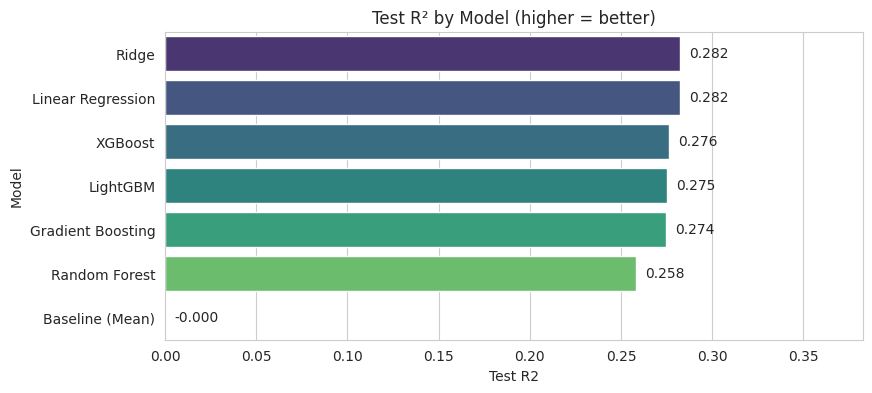

In [8]:
plt.figure(figsize=(9, 4))
sns.barplot(data=results, y="Model", x="Test R2", palette="viridis")
plt.title("Test R² by Model (higher = better)"); plt.xlim(0, results["Test R2"].max() + .1)
for i, v in enumerate(results["Test R2"]): plt.text(v + .005, i, f"{v:.3f}", va="center")
plt.show()

### **Hyperparameter tuning of the best boosting model**
We run a small random search on LightGBM (a fast & strong model for tabular data).

In [9]:
search = RandomizedSearchCV(
    Pipeline([("prep", make_prep(False)), ("model", LGBMRegressor(random_state=SEED, verbose=-1))]),
    param_distributions={
        "model__n_estimators": [200, 400, 600],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "model__max_depth": [2, 3, 4, 5],
        "model__num_leaves": [7, 15, 31],
        "model__min_child_samples": [20, 40, 80],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__reg_lambda": [0, 1, 5, 10]},
    n_iter=20, cv=kf, scoring="r2", random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
best = search.best_estimator_
pred = best.predict(X_test)
print("Best params:", {k.replace("model__",""): v for k, v in search.best_params_.items()})
tuned_pred = best.predict(X_test)
print(f"Tuned LightGBM -> R2: {r2_score(y_test, tuned_pred):.4f} | MAE: {mean_absolute_error(y_test, tuned_pred):.2f} | RMSE: {np.sqrt(mean_squared_error(y_test, tuned_pred)):.2f}")

# pick the final model = best Test R2 among all models (tuned LightGBM included)
fitted["Tuned LightGBM"] = best
scores = {n: r2_score(y_test, m.predict(X_test)) for n, m in fitted.items()}
final_name = max(scores, key=scores.get)
pred = fitted[final_name].predict(X_test)
print("Final model:", final_name, "| Test R2 =", round(scores[final_name], 4))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

Best params: {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 31, 'n_estimators': 600, 'min_child_samples': 40, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.8}
Tuned LightGBM -> R2: 0.2784 | MAE: 7.37 | RMSE: 10.26
Final model: Ridge | Test R2 = 0.2824


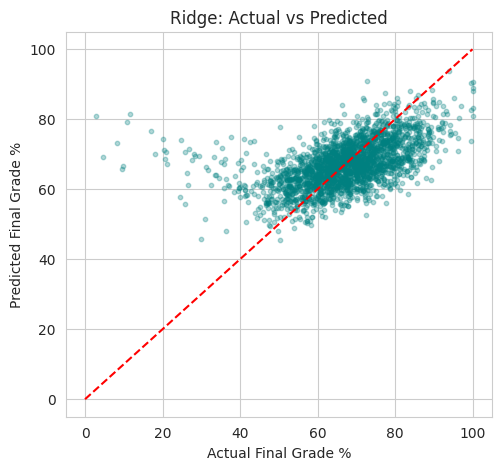

In [10]:
plt.figure(figsize=(5.5, 5))
plt.scatter(y_test, pred, alpha=.3, s=10, color="teal")
plt.plot([0, 100], [0, 100], "r--"); plt.xlabel("Actual Final Grade %"); plt.ylabel("Predicted Final Grade %")
plt.title(f"{final_name}: Actual vs Predicted"); plt.show()

### **Why is R² not close to 1?**
About 2% of students have a very low final grade (< 40%, the "F" group) that the features cannot explain (these rows look like random shocks, e.g. illness or dropout). Such outliers add large errors. Let's also score the model on **typical students** (actual grade ≥ 40).

In [11]:
mask = y_test.values >= 40
print(f"Share of low-grade outliers in test set: {(~mask).mean():.1%}")
print(f"R2 on all students     : {r2_score(y_test, pred):.3f}")
print(f"R2 on typical students : {r2_score(y_test[mask], pred[mask]):.3f}")
print(f"MAE on typical students: {mean_absolute_error(y_test[mask], pred[mask]):.2f} grade points")

Share of low-grade outliers in test set: 2.2%
R2 on all students     : 0.282
R2 on typical students : 0.382
MAE on typical students: 6.64 grade points


## **7. Feature Importance**
Which inputs matter most? (from the tuned LightGBM)

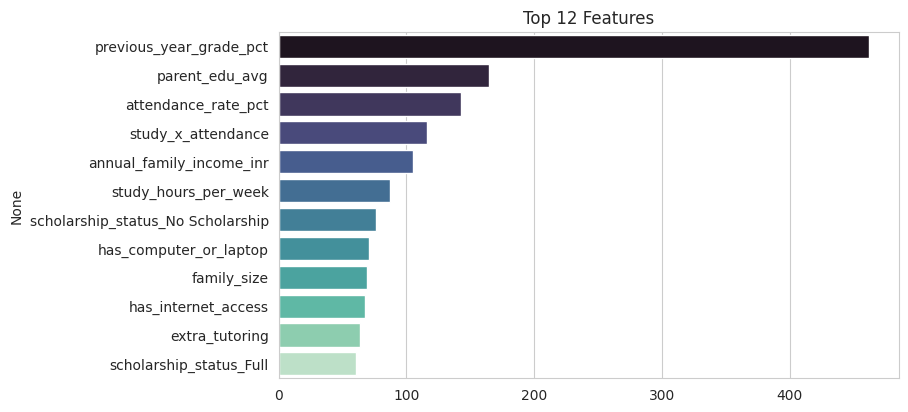

In [12]:
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(12)
imp.index = [i.replace("num__","").replace("cat__","") for i in imp.index]
plt.figure(figsize=(8, 4.5)); sns.barplot(x=imp.values, y=imp.index, palette="mako")
plt.title("Top 12 Features"); plt.show()

## **8. Bonus: Predict the Letter Grade (A–F)**
We convert the predicted % into grade letters using the dataset's own cut-offs (A ≥ 90, B ≥ 75, C ≥ 60, D ≥ 40, else F).

Letter-grade accuracy: 0.575


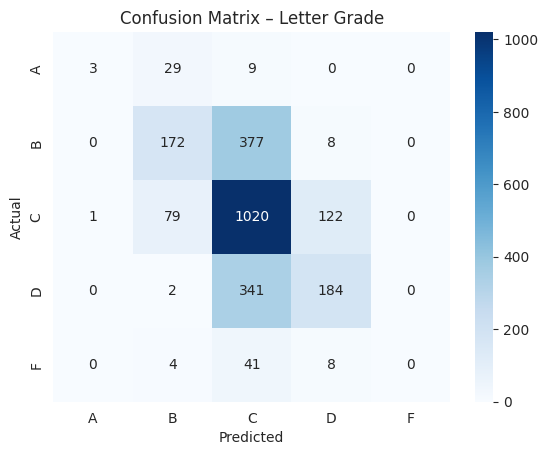

In [13]:
def to_class(p):
    return np.select([p >= 90, p >= 75, p >= 60, p >= 40], ["A","B","C","D"], "F")

true_cls, pred_cls = to_class(y_test.values), to_class(pred)
print(f"Letter-grade accuracy: {accuracy_score(true_cls, pred_cls):.3f}")
labels = ["A","B","C","D","F"]
sns.heatmap(confusion_matrix(true_cls, pred_cls, labels=labels), annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix – Letter Grade"); plt.show()

## **9. Conclusion**

In [14]:
print(f"Final model        : {final_name}")
print(f"Test R2 / MAE      : {r2_score(y_test, pred):.3f} / {mean_absolute_error(y_test, pred):.2f} grade points")
print(f"R2 (typical, >=40) : {r2_score(y_test[mask], pred[mask]):.3f}")
print(f"Letter accuracy    : {accuracy_score(true_cls, pred_cls):.1%} (always predicting 'C' gives {(true_cls=='C').mean():.1%})")

Final model        : Ridge
Test R2 / MAE      : 0.282 / 7.33 grade points
R2 (typical, >=40) : 0.382
Letter accuracy    : 57.5% (always predicting 'C' gives 50.9%)


### **✅ Summary**
- **Task:** predict students' final grade % from family background (SES), school and study-habit data.
- **Data prep:** removed duplicates, imputed missing values, dropped `grade_class` & `at_risk_flag` to **avoid data leakage**, and added 3 simple features.
- **Models:** the mean baseline scores R² ≈ 0. Linear/Ridge regression and the boosted trees (XGBoost, LightGBM, Gradient Boosting) all land close together, with the simple linear models slightly ahead – the relationships in this data are mostly linear, so complex models add little. Tuning LightGBM did not beat Ridge. The final model is chosen automatically by test R².
- **Realistic accuracy:** R² is moderate (about 0.3 on all students, higher on typical students) because ~2% of students have very low grades the features cannot explain. Typical error is about 7 grade points.
- **Key drivers:** previous-year grade, family income, study hours, attendance, and digital access (internet/computer) matter most.
- **Letter grades:** predicted letters are right more often than always guessing "C", but borderline cases are hard.
- **Practical use:** a school could flag students likely to score low early and give them tutoring or support.

### **⚠️ Limitations & next steps**
- Part of a student's final grade is not in the data (motivation, teacher quality), so R² cannot reach 1.0.
- Try more feature engineering, stacking/ensembling, or a classification model focused on the rare at-risk group.
- Predictions are for support and planning, not for judging individual students.

*If you found this helpful, please upvote 👍*